# 2️⃣ 효과: 과거 외국인 할인 프로모션 DiD

**질문**: 할인을 한 동에 외국인이 더 왔나 / 카드 소비가 달라졌나

**결과 변수**
- **주 지표: 외국인 방문 (SKT)** — 결제수단과 무관하게 잡힘
- 보조 지표: 외국인 카드 소비 (음식·소매) — 할인은 알리페이 결제에만 적용되므로 카드에는 직접 잡히지 않음. 감소하면 "카드 → QR 전환" 신호로 해석

**방법 (DiD)**: 시행 동의 변화 − 비슷한 비시행 동의 변화
1. 비교 동: 같은 성격의 후보군(시장 → 동지역, 애월 → 읍면) 중 시행 전 12개월 방문(또는 소비) 추이가 시행 동과 가장 비슷한 5개
2. 효과 = (시행 동 − 비교 동) 격차가 시행 기간에 시행 전보다 얼마나 벌어졌나 (로그 → %)
3. 우연인지 확인: 후보군의 동 하나씩을 '가짜 시행 동'으로 놓고 똑같이 계산 → 진짜 효과가 가짜들보다 큰지 (플라시보 p값)

- 데이터: `마스터_B_동월.csv`

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False

B = pd.read_csv('마스터_B_동월.csv', encoding='utf-8-sig')
A = pd.read_csv('마스터_A_동.csv', encoding='utf-8-sig')
B['ym'] = pd.PeriodIndex(B.기준연월.astype(str), freq='M')
ZONE = dict(zip(A.행정동명, A.권역))

# 로그 패널 (동 = 열, 월 = 행)
PANEL = {
    '방문': B.pivot(index='ym', columns='행정동명', values='방문').pipe(np.log),
    '카드': B.pivot(index='ym', columns='행정동명', values='금액_음식소매').clip(lower=1).pipe(np.log),
}

## 1. 이력표 (2-1)
DiD에는 시작·종료일이 확실하고 비교 동이 있는 1~3회차만 사용.

In [ ]:
HIST = pd.DataFrame([
    (1, '2024.4~5',  '동문재래시장, 서귀포매일올레시장', '일도1동, 중앙동', '알리페이+', '최대 50% (1인 1회)', '사용 (2회차와 묶음)'),
    (2, '2024.6~7',  '1회차 연장', '일도1동, 중앙동', '알리페이+', '20%', '사용 (1회차와 묶음)'),
    (3, '2024.8~9',  '애월 카페거리(36곳), 대중교통', '애월읍 (+전역 버스)', '알리페이, 제로페이', '최대 50% (카페 5천 원, 1인 1회)', '사용'),
    (4, '2025.?~12', '애월 카페거리, 전통시장', '애월읍, 일도1동·중앙동 추정', '모바일페이', '10% (최대 1만 원, 1인 1회)', '미사용 (시작 월 미확인)'),
    (5, '2026.7~8',  '전역 제로페이 가맹점 약 3.2만 곳', '전역', '알리페이+ 외 해외 월렛', '20%', '미사용 (비교 동 없음)'),
], columns=['회차', '기간', '대상', '행정동', '결제수단', '할인', 'DiD'])
HIST

## 2. 분석 설정
- **시장(1·2회차)**: 시행 2024.04~07, 비교 후보 = 동지역 동 (다른 회차 시행 동 제외)
- **애월(3회차)**: 시행 2024.08~09, 비교 후보 = 읍면 (애월읍, 섬인 추자·우도 제외)
- 시행 전 기간: 시작 직전 12개월

In [ ]:
EXCL = {'일도1동', '중앙동', '애월읍', '추자면', '우도면'}
POOL_DONG = [d for d in ZONE if '동지역' in ZONE[d] and d not in EXCL]
POOL_EUP  = [d for d in ZONE if '동지역' not in ZONE[d] and d not in EXCL]

CASES = [
    ('1·2회차 시장 (일도1동+중앙동)', ['일도1동', '중앙동'], POOL_DONG, '2024-04', '2024-07'),
    ('1·2회차 일도1동',              ['일도1동'],           POOL_DONG, '2024-04', '2024-07'),
    ('1·2회차 중앙동',               ['중앙동'],            POOL_DONG, '2024-04', '2024-07'),
    ('3회차 애월읍',                 ['애월읍'],            POOL_EUP,  '2024-08', '2024-09'),
]
PRE_N, K = 12, 5

## 3. DiD + 플라시보 함수

In [ ]:
def did(P, treat, pool, start, end, k=K, pre_n=PRE_N):
    s, e = pd.Period(start, 'M'), pd.Period(end, 'M')
    pre = P.loc[s - pre_n: s - 1]
    tr = P[treat].mean(axis=1)
    cor = pre[pool].apply(lambda c: np.corrcoef(c, tr.loc[pre.index])[0, 1])
    ctrl = cor.nlargest(k).index.tolist() if k else list(pool)
    gap = tr - P[ctrl].mean(axis=1)
    eff = gap.loc[s:e].mean() - gap.loc[s - pre_n: s - 1].mean()
    return eff, ctrl, gap

def run(P, treat, pool, start, end, k=K):
    eff, ctrl, gap = did(P, treat, pool, start, end, k)
    placebo = np.array([did(P, [d], [x for x in pool if x != d], start, end, k)[0] for d in pool])
    p = (np.abs(placebo) >= abs(eff)).mean()
    return dict(효과_로그=eff, 효과_퍼센트=np.expm1(eff) * 100, 플라시보_p=p, 비교동=', '.join(ctrl)), gap, placebo

## 4. 결과

In [ ]:
rows, GAPS, PLAC = [], {}, {}
for var, P in PANEL.items():
    for label, treat, pool, s, e in CASES:
        r, gap, plac = run(P, treat, pool, s, e)
        rows.append({'지표': var, '사례': label, **r})
        GAPS[(var, label)] = (gap, s, e); PLAC[(var, label)] = (plac, r['효과_로그'])
RES = pd.DataFrame(rows)
RES.round({'효과_로그': 3, '효과_퍼센트': 1, '플라시보_p': 2})

## 5. 격차 추이 (시행 동 − 비교 동)
시행 전 평균을 0으로 맞춤. 회색 = 시행 기간. 시행 기간에 선이 위로 튀면 효과.

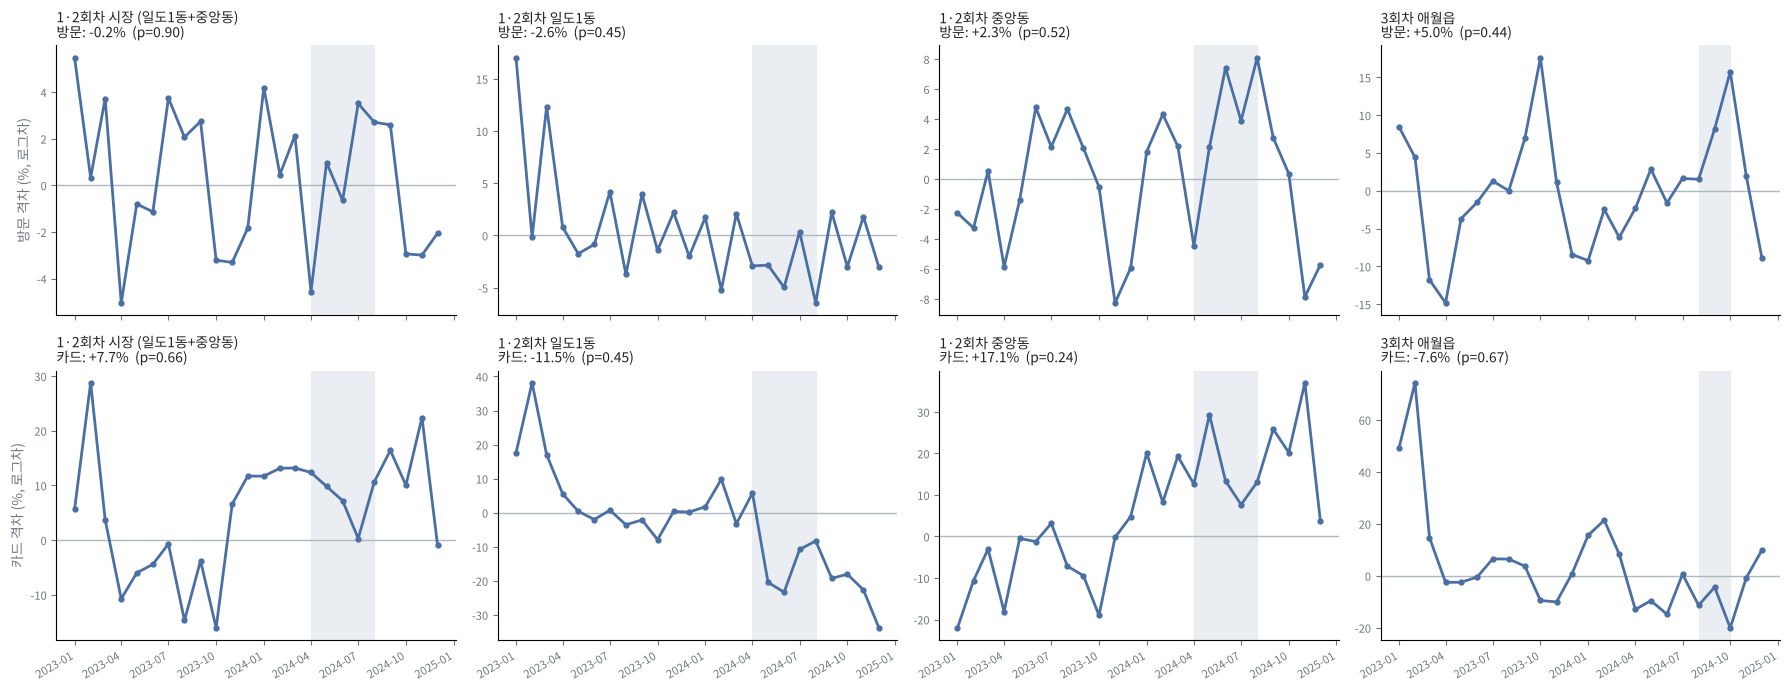

In [ ]:
INK, MUTED, LINE, SHADE = '#1f2328', '#6e7781', '#4a6fa5', '#eaeef2'
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for i, var in enumerate(PANEL):
    for j, (label, *_rest) in enumerate(CASES):
        ax = axes[i, j]; gap, s, e = GAPS[(var, label)]
        s_, e_ = pd.Period(s, 'M'), pd.Period(e, 'M')
        g = (gap - gap.loc[s_ - PRE_N: s_ - 1].mean()).loc['2023-01':'2024-12']
        x = g.index.to_timestamp()
        ax.axvspan(s_.to_timestamp(), (e_ + 1).to_timestamp(), color=SHADE, zorder=0)
        ax.axhline(0, color='#afb8c1', lw=1)
        ax.plot(x, g.values * 100, color=LINE, lw=2, marker='o', ms=3.5)
        r = RES[(RES.지표 == var) & (RES.사례 == label)].iloc[0]
        ax.set_title(f'{label}\n{var}: {r.효과_퍼센트:+.1f}%  (p={r.플라시보_p:.2f})', fontsize=10, color=INK, loc='left')
        ax.tick_params(colors=MUTED, labelsize=8)
        for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
        if j == 0: ax.set_ylabel(f'{var} 격차 (%, 로그차)', color=MUTED)
fig.autofmt_xdate()
plt.tight_layout(); plt.savefig('DiD_격차추이.png', dpi=200, bbox_inches='tight'); plt.show()

## 6. 플라시보 분포
회색 막대 = 가짜 시행 동들의 '효과', 주황 선 = 진짜 시행 동. 주황 선이 분포 끝에 있어야 우연이 아니라고 볼 수 있음.

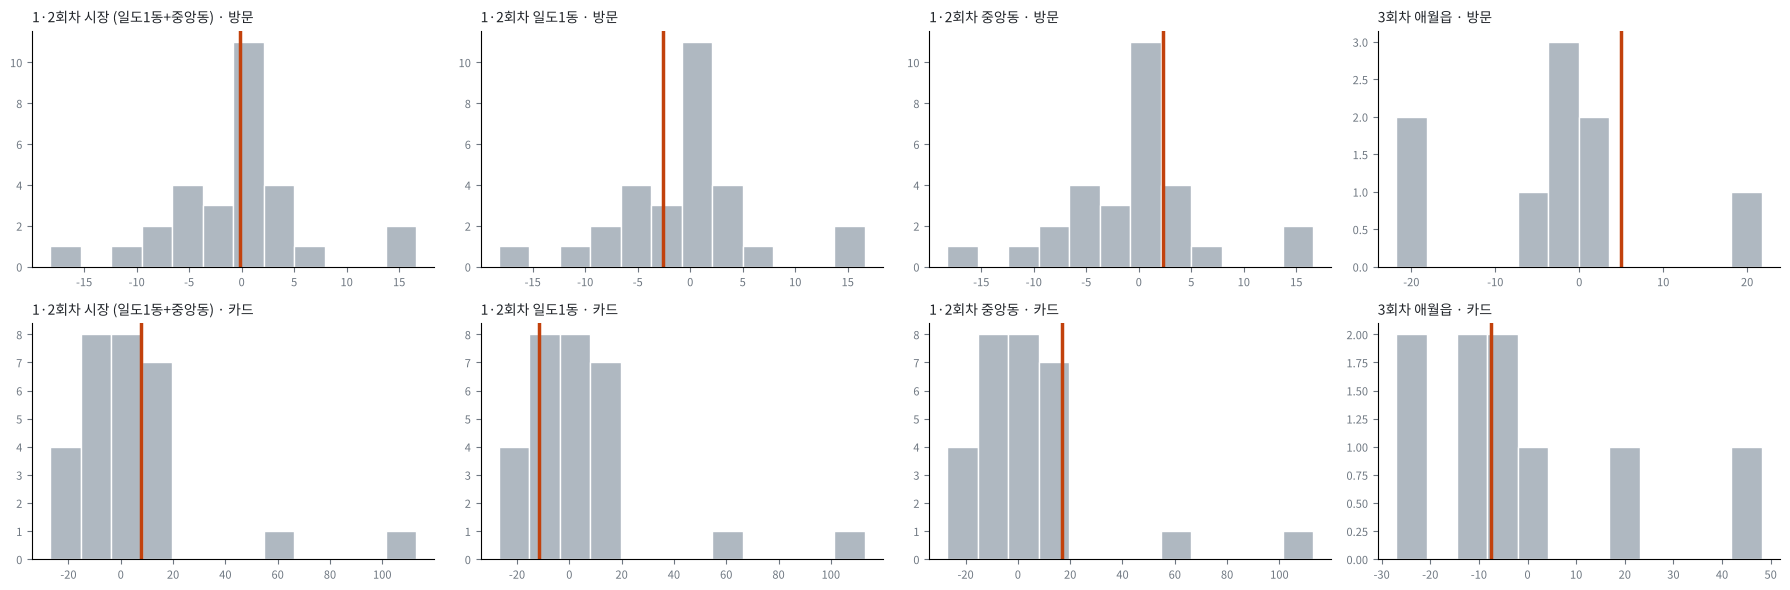

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for i, var in enumerate(PANEL):
    for j, (label, *_r) in enumerate(CASES):
        ax = axes[i, j]; plac, eff = PLAC[(var, label)]
        ax.hist(np.expm1(plac) * 100, bins=12, color='#afb8c1', edgecolor='white')
        ax.axvline(np.expm1(eff) * 100, color='#c2410c', lw=2.5)
        ax.set_title(f'{label} · {var}', fontsize=10, color=INK, loc='left')
        ax.tick_params(colors=MUTED, labelsize=8)
        for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('DiD_플라시보.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. 민감도: 비교 동 개수를 바꿔도 같은가 (3개 / 5개 / 후보 전체)

In [ ]:
rows = []
for var, P in PANEL.items():
    for label, treat, pool, s, e in CASES:
        for k in [3, 5, None]:
            r, _, _ = run(P, treat, pool, s, e, k)
            rows.append({'지표': var, '사례': label, '비교동수': k or '전체', '효과_퍼센트': round(r['효과_퍼센트'], 1), '플라시보_p': round(r['플라시보_p'], 2)})
pd.DataFrame(rows).pivot_table(index=['지표', '사례'], columns='비교동수', values=['효과_퍼센트', '플라시보_p'], aggfunc='first')

## 8. 결론

**방문 (주 지표)**
- 1~3회차 모두 시행 동의 외국인 방문이 비교 동보다 유의하게 늘지 않음 (효과 −3% ~ +5%, 플라시보 p 0.4 이상)
- → **과거 프로모션의 방문 유인 효과는 우리 데이터에서 확인되지 않음**

**카드 소비 (보조)**
- 일도1동은 감소, 중앙동은 증가로 방향이 엇갈리고 모두 유의하지 않음
- 할인이 알리페이 결제에만 적용되므로 카드 소비로는 할인 효과를 직접 볼 수 없음

**해석 시 한계**
- 할인 대상(시장, 카페 36곳)이 동 전체보다 훨씬 좁아 동 단위에서는 효과가 묻힐 수 있음
- 방문은 30분 이상 체류 기준이라 시장처럼 짧게 들르는 곳은 과소 집계
- 시행 동이 1~2개라 검정력이 낮음 (효과가 없다는 증거가 아니라, 검출되지 않았다는 의미)
- 3회차 대중교통 할인은 전역 대상이라 비교 동도 일부 영향

**→ 파이프라인 처리**: 3️⃣ 시뮬레이션의 효과값은 문헌값 기반 시나리오(낮음·중간·높음)로 대체.
공개된 성과("알리페이 결제 3월 대비 +1,454%")는 QR 채널 성장이며, 카드 → QR 전환분이 포함되어 순수한 소비 증가로 볼 수 없음.